# Task 3: Classifier Training, Multi-Class Evaluation & Holdout Comparison
## Machine Learning & AI Case Study: Arrhythmia Detection & Classification

**Task Ownership: Group Member 3**

### Objectives:
1. Load balanced training and test sets for both **Beat-Holdout** and **Patient-Holdout** protocols.
2. Apply stratified subsampling to preserve exact class proportions while ensuring feasible training.
3. Train **Support Vector Classifier (SVM)** with non-linear RBF kernel (`C=10.0, gamma='scale'`).
4. Train **Random Forest Classifier** (`n_estimators=150, max_depth=15`).
5. Evaluate multi-class classification performance: Accuracy, Precision, Recall, Macro F1, Weighted F1.
6. Generate normalized confusion matrices for all 4 model-split configurations (`confusion_matrices_comparison.png`).
7. Analyze the performance gap between intra-patient data leakage (Beat-Holdout) and realistic clinical deployment (Patient-Holdout).


In [1]:
# Step 1: Library Imports
import os
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
from scipy.stats import spearmanr

# Set styling
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150

print("Libraries imported successfully.")


Libraries imported successfully.


### Step 2: Data Loading & Separation of Signals, Labels, and Patient IDs

Each ECG heartbeat sample has **277 columns**:
- Columns `0` to `274`: **275 ECG signal amplitude points** (centered at R-peak ~ index 137).
- Column `275`: **Class Label** (numeric 1.0 to 8.0).
- Column `276`: **Patient Number** (e.g., 100 to 234).

We load the beat-holdout and patient-holdout CSVs and safely separate features from metadata.


In [2]:
# Mapping of numeric identifiers to cardiology beat classes
CLASS_MAPPING = {
    1: 'Normal (N)',
    2: 'LBBB (L)',
    3: 'RBBB (R)',
    4: 'PVC (V)',
    5: 'APB (A)',
    6: 'Fusion Normal/Ventricular (F)',
    7: 'Fusion Paced/Normal (f)',
    8: 'Paced Beat (/)'
}

CLASS_NAMES = ['N', 'L', 'R', 'V', 'A', 'F', 'f', '/']

def load_data(train_path, test_path, n_time=275):
    """
    Safely load ECG CSV data, separating 275 signal features from labels and patient IDs.
    """
    print(f"Loading {os.path.basename(train_path)} and {os.path.basename(test_path)}...")
    tr = pd.read_csv(train_path, header=None).values
    te = pd.read_csv(test_path, header=None).values
    
    X_train = tr[:, :n_time].astype(np.float32)
    y_train = tr[:, n_time].astype(int)
    
    X_test  = te[:, :n_time].astype(np.float32)
    y_test  = te[:, n_time].astype(int)
    
    pat_train = tr[:, n_time + 1].astype(int) if tr.shape[1] > n_time + 1 else None
    pat_test  = te[:, n_time + 1].astype(int) if te.shape[1] > n_time + 1 else None
    
    print(f"  Train: X={X_train.shape}, y={y_train.shape}")
    print(f"  Test:  X={X_test.shape}, y={y_test.shape}")
    return X_train, y_train, X_test, y_test, pat_train, pat_test

# Load both split datasets
X_tr_b, y_tr_b, X_te_b, y_te_b, pat_tr_b, pat_te_b = load_data('train_beats.csv', 'test_beats.csv')
X_tr_p, y_tr_p, X_te_p, y_te_p, pat_tr_p, pat_te_p = load_data('train_patients.csv', 'test_patients.csv')


Loading train_beats.csv and test_beats.csv...
  Train: X=(30992, 275), y=(30992,)
  Test:  X=(37442, 275), y=(37442,)
Loading train_patients.csv and test_patients.csv...
  Train: X=(200352, 275), y=(200352,)
  Test:  X=(14482, 275), y=(14482,)


### Step 3: Class Distribution Inspection
Let's inspect the class balances in the training sets (balanced through resampling) and the test sets.


In [3]:
# Inspect class distribution
def print_class_distribution(y, title):
    classes, counts = np.unique(y, return_counts=True)
    print(f"--- {title} ---")
    for c, count in zip(classes, counts):
        print(f"  Class {c} ({CLASS_MAPPING.get(c, 'Unknown')}): {count} samples ({count/len(y)*100:.2f}%)")
    print(f"  Total: {len(y)} samples\n")

print_class_distribution(y_tr_b, "Beat-Holdout Train Set (Resampled)")
print_class_distribution(y_te_b, "Beat-Holdout Test Set (Natural Distribution)")
print_class_distribution(y_tr_p, "Patient-Holdout Train Set (Resampled)")
print_class_distribution(y_te_p, "Patient-Holdout Test Set (Unseen Patients: 104, 208, 113, 210, 119)")


--- Beat-Holdout Train Set (Resampled) ---
  Class 1 (Normal (N)): 3874 samples (12.50%)
  Class 2 (LBBB (L)): 3874 samples (12.50%)
  Class 3 (RBBB (R)): 3874 samples (12.50%)
  Class 4 (PVC (V)): 3874 samples (12.50%)
  Class 5 (APB (A)): 3874 samples (12.50%)
  Class 6 (Fusion Normal/Ventricular (F)): 3874 samples (12.50%)
  Class 7 (Fusion Paced/Normal (f)): 3874 samples (12.50%)
  Class 8 (Paced Beat (/)): 3874 samples (12.50%)
  Total: 30992 samples

--- Beat-Holdout Test Set (Natural Distribution) ---
  Class 1 (Normal (N)): 28474 samples (76.05%)
  Class 2 (LBBB (L)): 1636 samples (4.37%)
  Class 3 (RBBB (R)): 2581 samples (6.89%)
  Class 4 (PVC (V)): 1307 samples (3.49%)
  Class 5 (APB (A)): 783 samples (2.09%)
  Class 6 (Fusion Normal/Ventricular (F)): 191 samples (0.51%)
  Class 7 (Fusion Paced/Normal (f)): 416 samples (1.11%)
  Class 8 (Paced Beat (/)): 2054 samples (5.49%)
  Total: 37442 samples

--- Patient-Holdout Train Set (Resampled) ---
  Class 1 (Normal (N)): 25044 s

### Step 4: Stratified Subsampling Function
Because SVM has quadratic/cubic complexity with sample size ($O(n^2)$ to $O(n^3)$), training on the full 100k+ beats is computationally prohibitive.
As instructed in the case study guide, we use **stratified subsampling** to preserve exact class ratios while speeding up model fitting and permutation evaluation.


In [4]:
def stratified_subsample(X, y, n=5000, seed=42):
    """
    Draw a stratified subsample preserving exact class proportions.
    """
    if n >= len(X):
        return X, y
    X_sub, _, y_sub, _ = train_test_split(
        X, y,
        train_size=n,
        stratify=y,
        random_state=seed
    )
    return X_sub, y_sub

# Prepare subsamples for training (N=8000 for training, N=3000 for 5-fold PFI)
X_train_b_sub, y_train_b_sub = stratified_subsample(X_tr_b, y_tr_b, n=8000, seed=42)
X_train_p_sub, y_train_p_sub = stratified_subsample(X_tr_p, y_tr_p, n=8000, seed=42)

# Smaller subsamples for Permutation Feature Importance (5 folds * 11 slices = 55 predictions)
X_pfi_b, y_pfi_b = stratified_subsample(X_tr_b, y_tr_b, n=3000, seed=42)
X_pfi_p, y_pfi_p = stratified_subsample(X_tr_p, y_tr_p, n=3000, seed=42)

print(f"Subsampled Beat-holdout train for modeling: {X_train_b_sub.shape}")
print(f"Subsampled Patient-holdout train for modeling: {X_train_p_sub.shape}")


Subsampled Beat-holdout train for modeling: (8000, 275)
Subsampled Patient-holdout train for modeling: (8000, 275)


## Step 5: Model Training & Evaluation

We train two complementary classifiers on each split strategy:
1. **Support Vector Classifier (SVM)** with RBF Kernel (`C=10.0, gamma='scale'`)
2. **Random Forest Classifier** (`n_estimators=150, max_depth=15, random_state=42`)

We evaluate both on:
- **Beat-Holdout Test Set**: Measures performance when beats from all patients appear in both train and test (intra-patient correlations present).
- **Patient-Holdout Test Set**: Measures true generalization to brand-new, unseen patients (crucial for clinical translation).


In [5]:
# Define classifiers
models = {
    'SVM (RBF)': SVC(kernel='rbf', C=10.0, gamma='scale', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=15, random_state=42, n_jobs=-1)
}

# Dictionary to hold trained models and predictions
trained_models = {}
eval_results = []

for split_name, (X_tr, y_tr, X_te, y_te) in [
    ('Beat-Holdout', (X_train_b_sub, y_train_b_sub, X_te_b, y_te_b)),
    ('Patient-Holdout', (X_train_p_sub, y_train_p_sub, X_te_p, y_te_p))
]:
    for model_name, clf_template in models.items():
        key = f"{model_name} [{split_name}]"
        print(f"Training {key}...")
        t0 = time.time()
        clf = clone(clf_template)
        clf.fit(X_tr, y_tr)
        fit_time = time.time() - t0
        
        # Predict on test set
        y_pred = clf.predict(X_te)
        
        acc = accuracy_score(y_te, y_pred)
        macro_f1 = f1_score(y_te, y_pred, average='macro', zero_division=0)
        weighted_f1 = f1_score(y_te, y_pred, average='weighted', zero_division=0)
        macro_prec = precision_score(y_te, y_pred, average='macro', zero_division=0)
        macro_rec = recall_score(y_te, y_pred, average='macro', zero_division=0)
        
        trained_models[key] = {
            'model': clf,
            'y_pred': y_pred,
            'y_true': y_te,
            'accuracy': acc,
            'macro_f1': macro_f1
        }
        
        eval_results.append({
            'Model': model_name,
            'Split': split_name,
            'Accuracy': acc,
            'Macro F1': macro_f1,
            'Weighted F1': weighted_f1,
            'Macro Precision': macro_prec,
            'Macro Recall': macro_rec,
            'Train Time (s)': fit_time
        })
        print(f"  -> Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f} | Time: {fit_time:.1f}s")

# Display comparative performance
df_eval = pd.DataFrame(eval_results)
display(df_eval)


Training SVM (RBF) [Beat-Holdout]...
  -> Accuracy: 0.9387 | Macro F1: 0.8212 | Time: 0.8s
Training Random Forest [Beat-Holdout]...
  -> Accuracy: 0.9379 | Macro F1: 0.8126 | Time: 1.4s
Training SVM (RBF) [Patient-Holdout]...
  -> Accuracy: 0.9434 | Macro F1: 0.5601 | Time: 0.9s
Training Random Forest [Patient-Holdout]...
  -> Accuracy: 0.9402 | Macro F1: 0.6342 | Time: 1.4s


,Model,Split,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Train Time (s)
0,SVM (RBF),Beat-Holdout,0.938652,0.821244,0.949640,0.774431,0.953029,0.810455
1,Random Forest,Beat-Holdout,0.937877,0.812613,0.946841,0.752881,0.949274,1.372413
2,SVM (RBF),Patient-Holdout,0.943447,0.560127,0.952118,0.536299,0.603045,0.890929
3,Random Forest,Patient-Holdout,0.940202,0.634167,0.948540,0.603983,0.689630,1.361573


### Step 6: Detailed Classification Reports and Confusion Matrices
Let's plot normalized confusion matrices for both SVM and Random Forest on both holdout splits.


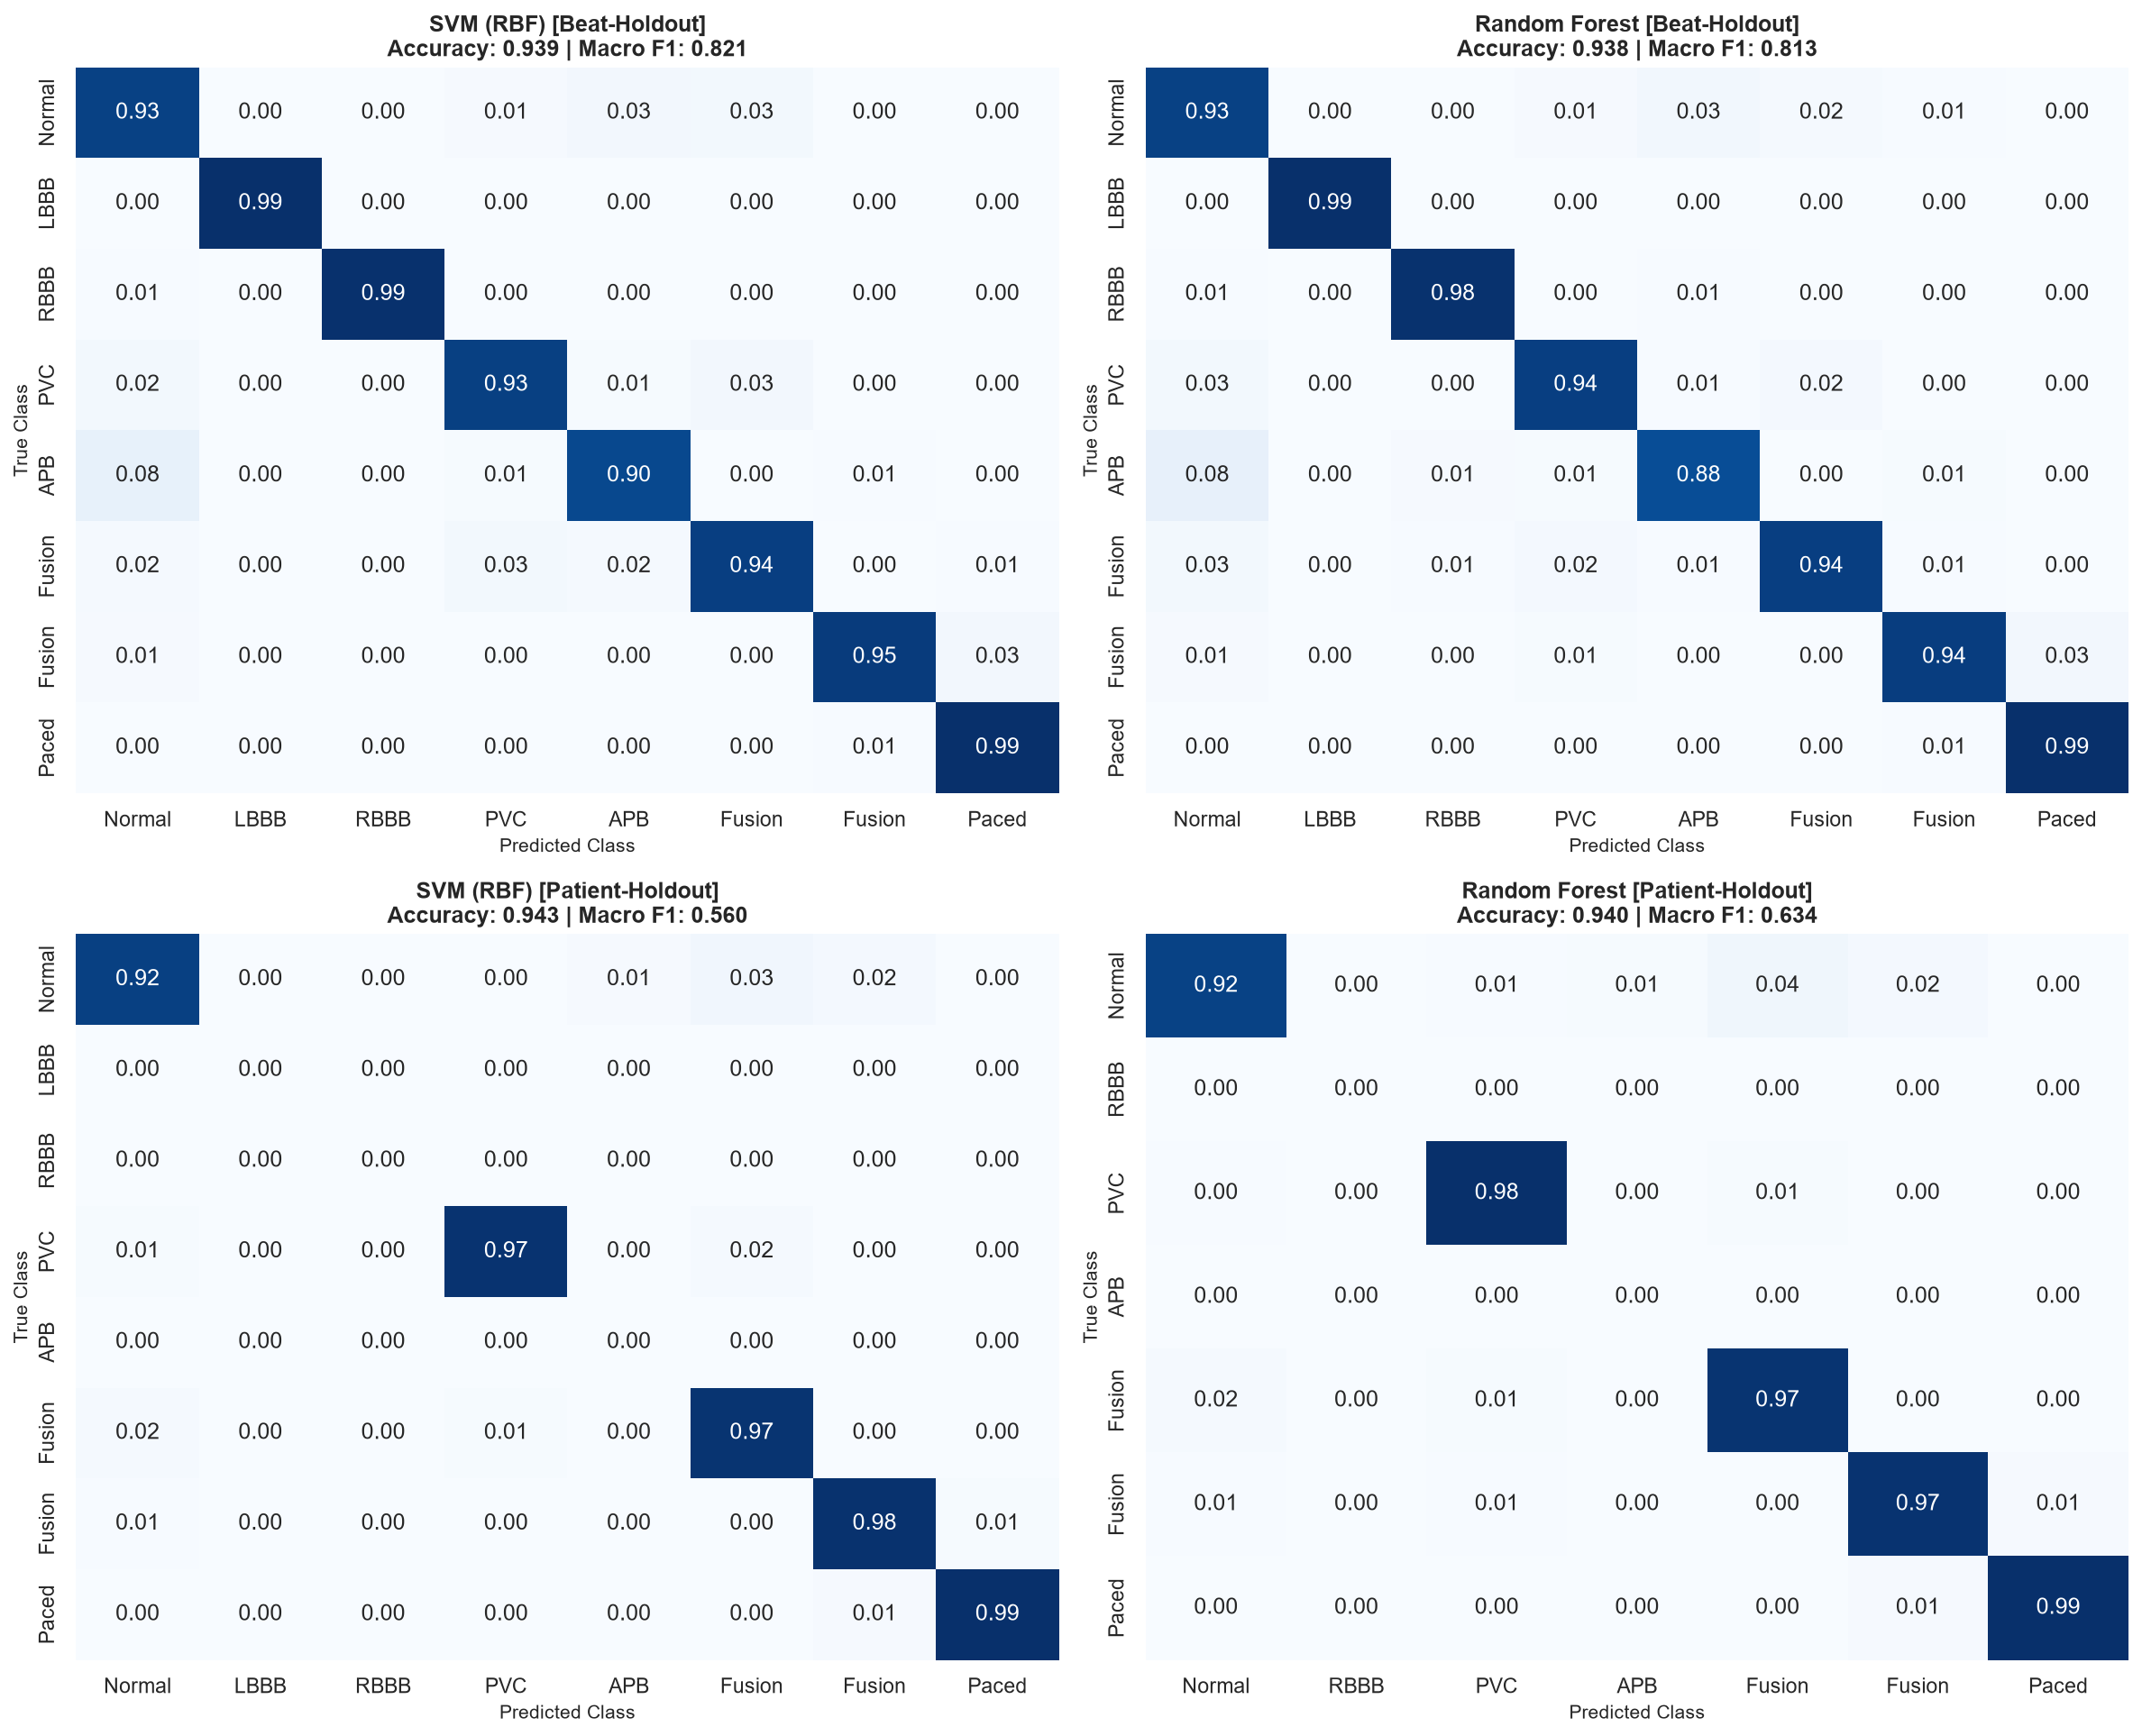

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes = axes.flatten()

for idx, (key, res) in enumerate(trained_models.items()):
    ax = axes[idx]
    y_true = res['y_true']
    y_pred = res['y_pred']
    
    # Present classes in test set
    present_classes = np.sort(np.unique(np.concatenate([y_true, y_pred])))
    tick_labels = [CLASS_MAPPING[c].split(' ')[0] for c in present_classes]
    
    cm = confusion_matrix(y_true, y_pred, labels=present_classes, normalize='true')
    
    sns.heatmap(
        cm, annot=True, fmt='.2f', cmap='Blues',
        xticklabels=tick_labels, yticklabels=tick_labels,
        ax=ax, cbar=False
    )
    ax.set_title(f"{key}\nAccuracy: {res['accuracy']:.3f} | Macro F1: {res['macro_f1']:.3f}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Predicted Class", fontsize=10)
    ax.set_ylabel("True Class", fontsize=10)

plt.tight_layout()
plt.savefig("confusion_matrices_comparison.png", dpi=300)
plt.show()
